### Visulize Keypoint from .npy files

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the connections between keypoints for pose visualization
POSE_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8),
    (0, 9), (9, 10), (10, 11), (11, 12), (12, 24), (24, 23), (23, 11),
    (11, 22), (22, 21), (21, 19), (19, 18), (18, 17), (17, 15), (15, 13),
    (13, 12), (11, 10), (12, 14), (14, 16), (15, 19), (16, 20), (23, 25),
    (24, 26)
]

def plot_pose(landmarks):
    # Create a new figure
    plt.figure(figsize=(5, 5))
    plt.xlim(-1, 1)
    plt.ylim(-1, 1)

    # Plot each keypoint
    for i, (x, y) in enumerate(landmarks):
        plt.scatter(x, y, c='blue', s=10)
        plt.text(x, y, f'{i}', fontsize=8, color='red')

    # Plot connections between keypoints
    for start, end in POSE_CONNECTIONS:
        x_start, y_start, _ = landmarks[start]
        x_end, y_end, _ = landmarks[end]
        plt.plot([x_start, x_end], [y_start, y_end], color='black')

    plt.gca().invert_yaxis()
    plt.show()

# Load the .npy file containing MediaPipe pose landmarks
file_path = 'C:/Users/araya/Desktop/vscode/Deep-learning-coding/MediaPipe/Data for different actions/train/ขโมย.mp4/ขโมย.npy'  # Replace with the actual file path
landmarks = np.load(file_path)

# Visualize the pose
plot_pose(landmarks)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Define the connections for visualization (pose, hands, and face)
POSE_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8),
    (0, 9), (9, 10), (10, 11), (11, 12), (12, 24), (24, 23), (23, 11),
    (11, 22), (22, 21), (21, 19), (19, 18), (18, 17), (17, 15), (15, 13),
    (13, 12), (11, 10), (12, 14), (14, 16), (15, 19), (16, 20), (23, 25),
    (24, 26)
]
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8),
    (5, 9), (9, 10), (10, 11), (11, 12), (9, 13), (13, 14), (14, 15),
    (15, 16), (13, 17), (17, 18), (18, 19), (19, 20)
]
FACE_CONNECTIONS = []  # Face connections can be very dense; you can skip or simplify them if needed

def plot_keypoints(keypoints, connections, color='black', ax=None):
    """Plots the keypoints with optional connections on a matplotlib axis."""
    if ax is None:
        ax = plt.gca()
    for i, (x, y) in enumerate(keypoints):
        ax.scatter(x, y, color='blue', s=5)
        # ax.text(x, y, str(i), fontsize=6, color='red')
    for start, end in connections:
        x_start, y_start = keypoints[start]
        x_end, y_end = keypoints[end]
        ax.plot([x_start, x_end], [y_start, y_end], color=color, linewidth=1)

def visualize_keypoints(data):
    # Split concatenated keypoints data into individual parts
    pose_keypoints = data[:66].reshape(-1, 2)
    left_hand_keypoints = data[66:108].reshape(-1, 2)
    right_hand_keypoints = data[108:150].reshape(-1, 2)
    face_keypoints = data[150:1086].reshape(-1, 2)

    # Create a plot to visualize the keypoints
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.invert_yaxis()  # Invert y-axis for correct orientation

    # Plot each part with corresponding connections
    plot_keypoints(pose_keypoints, POSE_CONNECTIONS, color='blue', ax=ax)
    plot_keypoints(left_hand_keypoints, HAND_CONNECTIONS, color='green', ax=ax)
    plot_keypoints(right_hand_keypoints, HAND_CONNECTIONS, color='orange', ax=ax)
    plot_keypoints(face_keypoints, FACE_CONNECTIONS, color='purple', ax=ax)

    plt.show()

# Load the .npy file containing MediaPipe pose, hand, and face landmarks
file_path = 'C:/Users/araya/Desktop/vscode/Deep-learning-coding/MediaPipe/Data for different actions/train/ขโมย.mp4/ขโมย.npy'  # Replace with the actual file path
keypoint_data = np.load(file_path)

# Visualize the keypoints
visualize_keypoints(keypoint_data)


[0.58278186 0.1640149  0.6072265  ... 0.11266844 0.6340939  0.1106102 ]
(1086,)


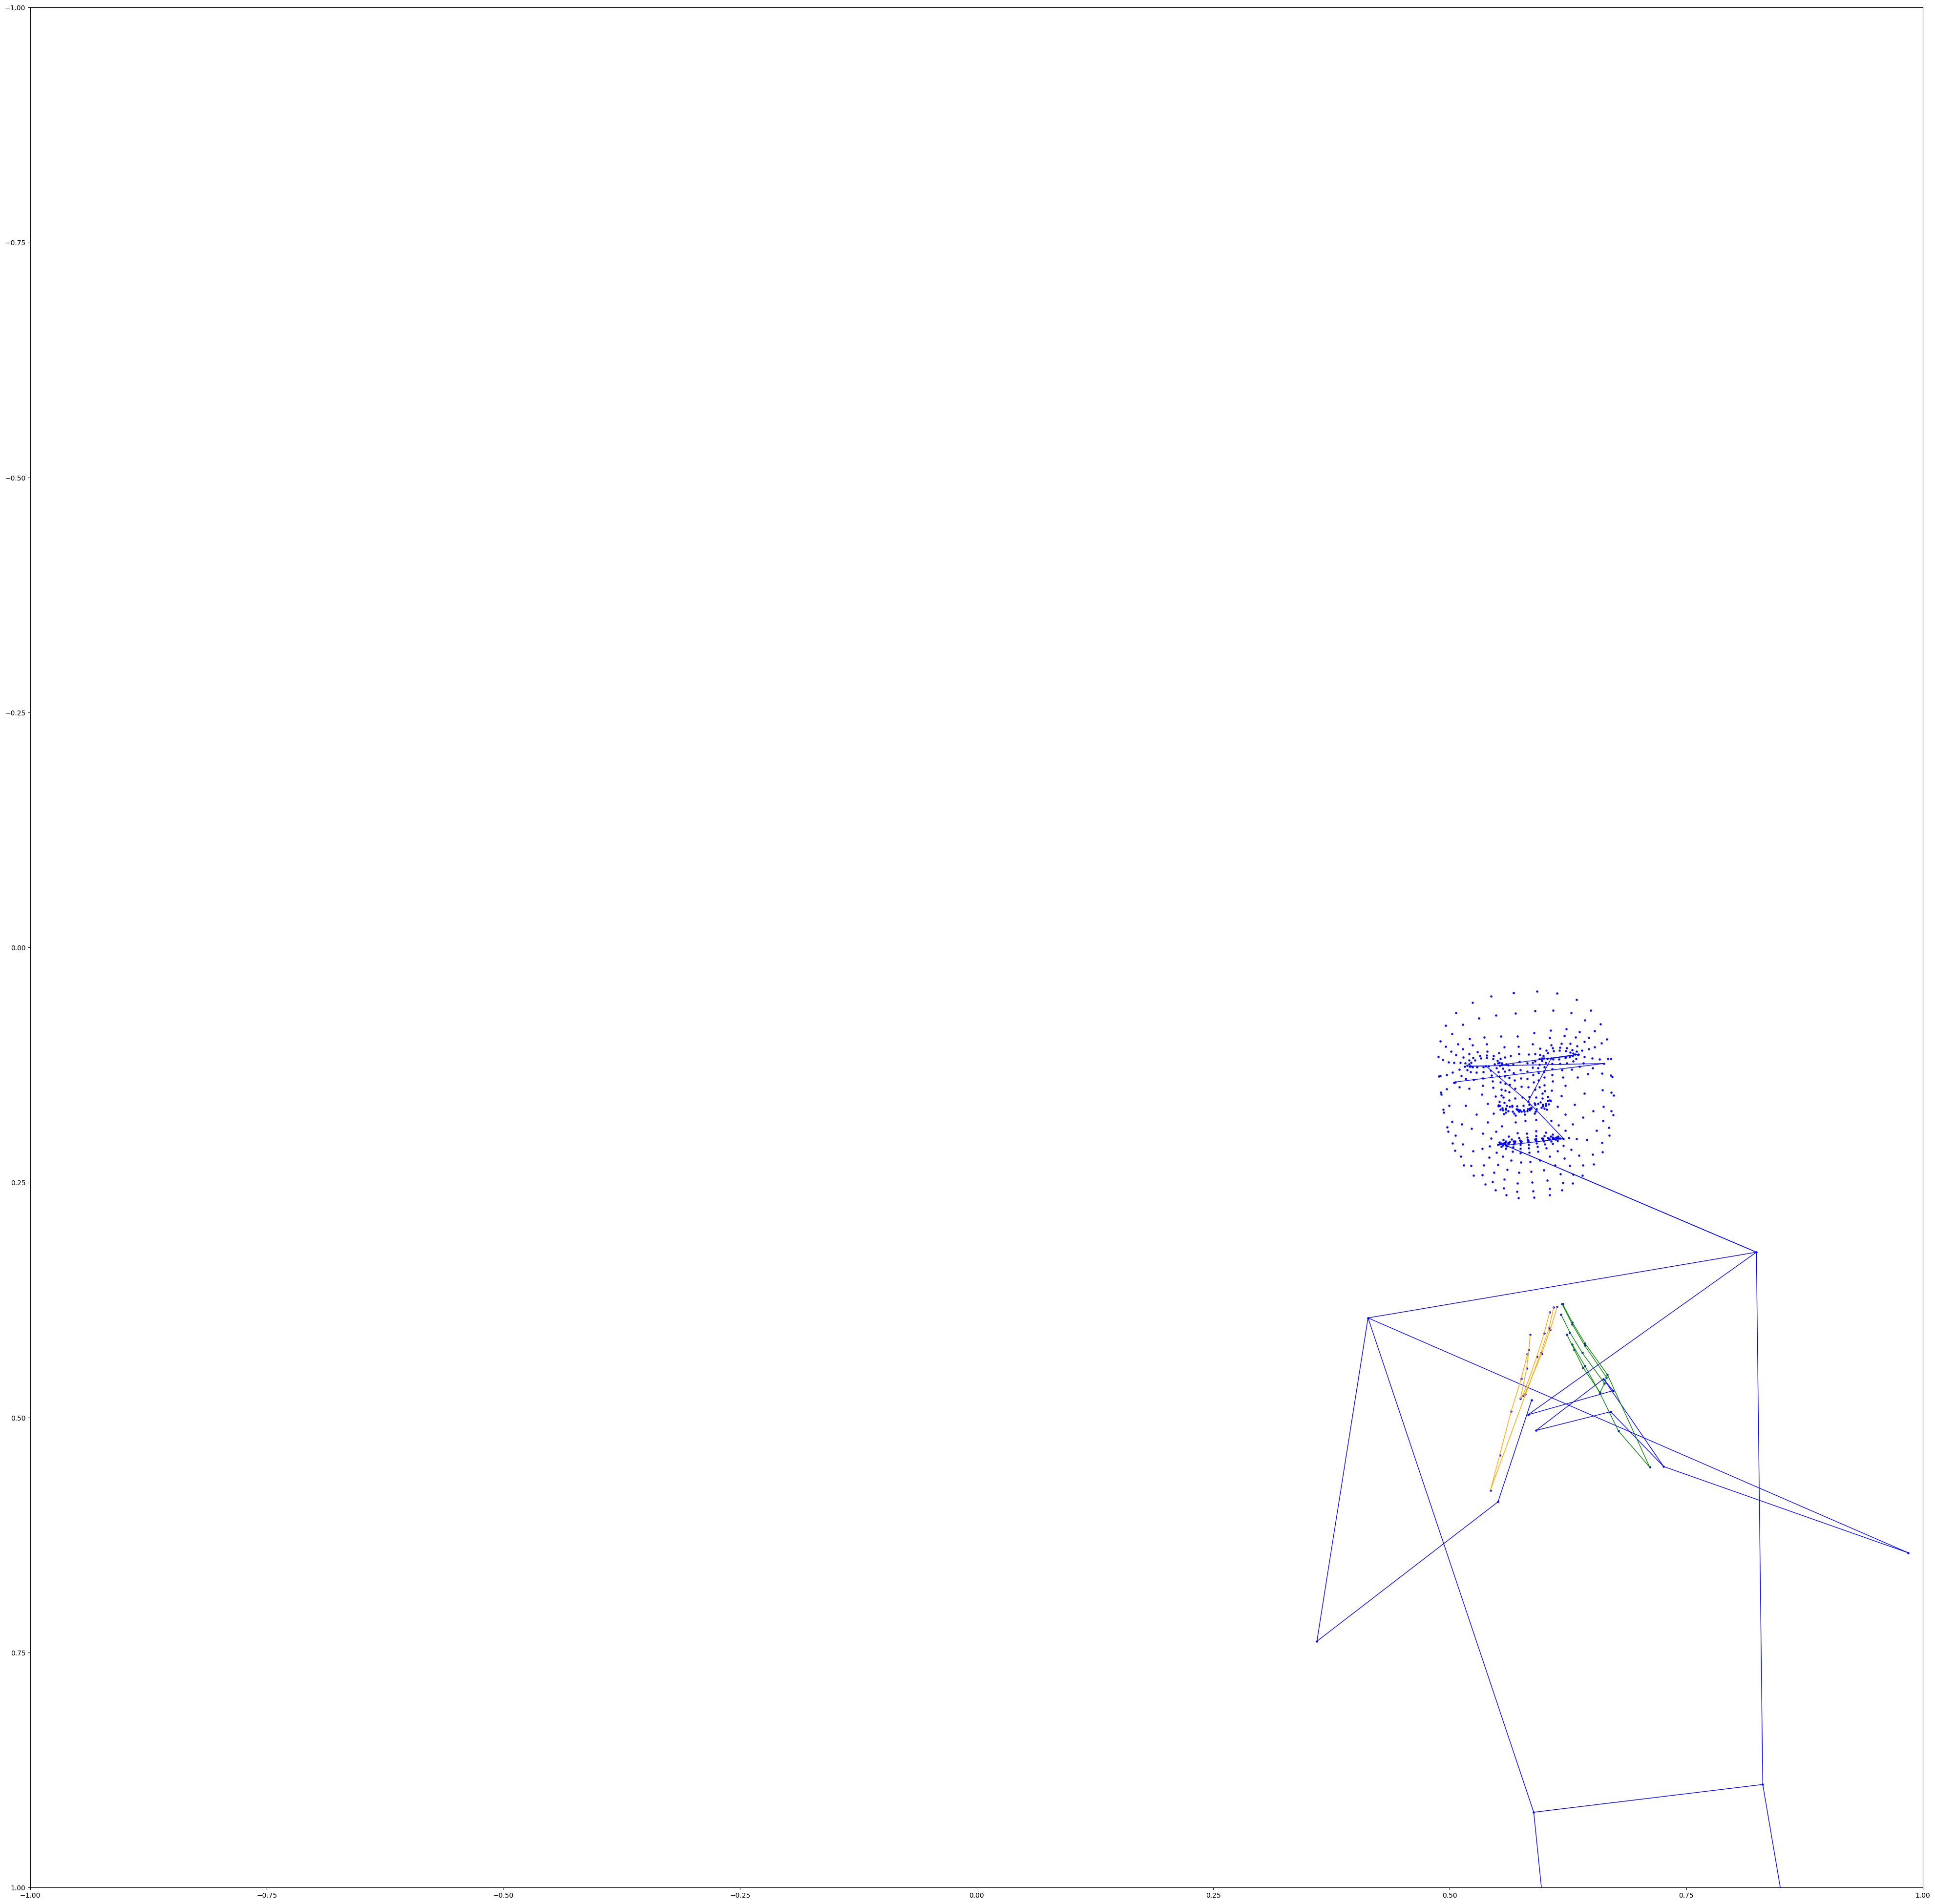

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import os
import time

# Define the connections for visualization (pose, hands, and face)
POSE_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8),
    (0, 9), (9, 10), (10, 11), (11, 12), (12, 24), (24, 23), (23, 11),
    (11, 22), (22, 21), (21, 19), (19, 18), (18, 17), (17, 15), (15, 13),
    (13, 12), (11, 10), (12, 14), (14, 16), (15, 19), (16, 20), (23, 25),
    (24, 26)
]
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4), (0, 5), (5, 6), (6, 7), (7, 8),
    (5, 9), (9, 10), (10, 11), (11, 12), (9, 13), (13, 14), (14, 15),
    (15, 16), (13, 17), (17, 18), (18, 19), (19, 20)
]

FACE_CONNECTIONS = []

def plot_keypoints(ax, keypoints, connections, color='black'):
    """Plots the keypoints with optional connections on a matplotlib axis."""
    ax.scatter(keypoints[:, 0], keypoints[:, 1], color='blue', s=5)
    for start, end in connections:
        x_start, y_start = keypoints[start]
        x_end, y_end = keypoints[end]
        ax.plot([x_start, x_end], [y_start, y_end], color=color, linewidth=1)

def visualize_keypoints_frame_by_frame(folder_path):
    # Get list of .npy files in the folder
    npy_files = sorted([f for f in os.listdir(folder_path) if f.endswith('.npy')])

    fig, ax = plt.subplots(figsize=(50, 50))
    ax.set_xlim(-1, 1)
    ax.set_ylim(-1, 1)
    ax.invert_yaxis()

    # Loop through each .npy file (frame by frame)
    for npy_file in npy_files:
        ax.clear()
        ax.set_xlim(-1, 1)
        ax.set_ylim(-1, 1)
        ax.invert_yaxis()

        # Load keypoints data from the .npy file
        keypoint_data = np.load(os.path.join(folder_path, npy_file))[63]

        print(keypoint_data)
        print(keypoint_data.shape)

        # Split data into parts
        pose_keypoints = keypoint_data[:66].reshape(-1, 2)
        left_hand_keypoints = keypoint_data[66:108].reshape(-1, 2)
        right_hand_keypoints = keypoint_data[108:150].reshape(-1, 2)
        face_keypoints = keypoint_data[150:1086].reshape(-1,2)

        # Plot keypoints for each part
        plot_keypoints(ax, face_keypoints, FACE_CONNECTIONS, color='purple')
        plot_keypoints(ax, pose_keypoints, POSE_CONNECTIONS, color='blue')
        plot_keypoints(ax, left_hand_keypoints, HAND_CONNECTIONS, color='green')
        plot_keypoints(ax, right_hand_keypoints, HAND_CONNECTIONS, color='orange')

        # Display the frame and pause briefly to simulate animation
        plt.draw()
        plt.pause(0.1)  # Adjust the pause duration for desired speed

    plt.show()

# Specify the folder containing your .npy files
folder_path = 'C:/Users/araya/Desktop/vscode/Deep-learning-coding/MediaPipe/Data for different actions/train/สวัสดี_4.mp4/'  # Replace with your actual folder path

# Visualize frames one by one
visualize_keypoints_frame_by_frame(folder_path)


In [ ]:
print(keypoint_data)